读取 `data/72/dat` 中的瞬态结果，对速度扰动执行等权离散内积下的 POD。结果和图像保存到 `results/72/POD`。

In [1]:
%matplotlib inline

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as mtri
from matplotlib.path import Path as MplPath
from scipy.linalg import eigh

plt.rcParams.update({
    'font.family': 'serif',
    'mathtext.fontset': 'stix',
    'font.size': 10,
    'axes.labelsize': 11,
    'axes.titlesize': 10,
    'figure.dpi': 140,
    'savefig.dpi': 300,
    'savefig.bbox': 'tight',
})

REPO_ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / 'pyproject.toml').exists() and (p / 'data').is_dir()
)
CASE_DIR = REPO_ROOT / 'data' / '72' / 'dat'
OUT_DIR = REPO_ROOT / 'results' / '72' / 'POD'
OUT_DIR.mkdir(parents=True, exist_ok=True)

FIELD_NAMES = ('x', 'y', 'rho', 'u', 'v', 'T', 'p', 'Ma', 'nu_tilde')
POD_FIELDS = ('u', 'v')
POD_RANK = 20

print(f'repository: {REPO_ROOT}')
print(f'case      : {CASE_DIR}')
print(f'output    : {OUT_DIR}')

repository: c:\Users\Administrator\Desktop\PurineCFD-Plugin
case      : c:\Users\Administrator\Desktop\PurineCFD-Plugin\data\72\dat
output    : c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\POD


每个快照只读取坐标和 `u、v`，时间由 `history.csv` 按步号匹配。

In [2]:
def step_number(path):
    return int(path.stem.split('_')[1])


snapshot_files = sorted(CASE_DIR.glob('step_*.dat'), key=step_number)
if not snapshot_files:
    raise FileNotFoundError(f'no step_*.dat files in {CASE_DIR}')

first = np.loadtxt(snapshot_files[0], skiprows=2, usecols=(0, 1, 3, 4))
x = first[:, 0]
y = first[:, 1]
n_snapshots = len(snapshot_files)
n_nodes = first.shape[0]
velocity = np.empty((n_snapshots, n_nodes, 2), dtype=np.float64)
velocity[0] = first[:, 2:4]

for i, path in enumerate(snapshot_files[1:], start=1):
    current = np.loadtxt(path, skiprows=2, usecols=(0, 1, 3, 4))
    if current.shape != first.shape:
        raise ValueError(f'incompatible shape in {path}: {current.shape}')
    if not np.allclose(current[:, :2], first[:, :2], rtol=0.0, atol=1e-12):
        raise ValueError(f'coordinates changed in {path}')
    velocity[i] = current[:, 2:4]

history_path = CASE_DIR / 'history.csv'
history = pd.read_csv(history_path)
steps = np.array([step_number(path) for path in snapshot_files], dtype=int)
time = np.interp(steps, history['step'].to_numpy(), history['time'].to_numpy())

print(f'nodes     : {n_nodes}')
print(f'snapshots : {n_snapshots}')
print(f'time      : {time[0]:.6f} ... {time[-1]:.6f} s')
print(f'dt        : {np.median(np.diff(time)):.6e} s')
print(f'fields    : {POD_FIELDS}')

nodes     : 62591
snapshots : 166
time      : 0.150300 ... 0.199800 s
dt        : 3.000000e-04 s
fields    : ('u', 'v')


去除时间平均场，将两个速度分量沿空间方向拼接为快照矩阵。

In [3]:
mean_velocity = velocity.mean(axis=0)
fluctuation = velocity - mean_velocity

# A has shape (spatial degrees of freedom, snapshots).
A = np.vstack((fluctuation[:, :, 0].T, fluctuation[:, :, 1].T))
print(f'A.shape   : {A.shape}')
print(f'A memory  : {A.nbytes / 1e6:.2f} MB')
print(f'mean norm : {np.linalg.norm(A.mean(axis=1)):.3e}')

A.shape   : (125182, 166)
A memory  : 166.24 MB
mean norm : 2.150e-11


用 snapshots 方法求解时间协方差矩阵，得到 POD 特征值、空间模态和时间振幅。

In [4]:
correlation = A.T @ A
eigenvalues, eigenvectors = eigh(correlation)
order = np.argsort(eigenvalues)[::-1]
eigenvalues = np.maximum(eigenvalues[order], 0.0)
eigenvectors = eigenvectors[:, order]

scale = max(eigenvalues[0], 1.0)
valid = eigenvalues > scale * 1e-12
n_valid = int(valid.sum())
rank = min(POD_RANK, n_valid)
if rank == 0:
    raise RuntimeError('no non-zero POD eigenvalue was found')

eigval = eigenvalues[:rank]
V = eigenvectors[:, :rank]
pod_modes = A @ V / np.sqrt(eigval)[None, :]
amplitudes = pod_modes.T @ A
energy_fraction = eigval / eigenvalues.sum()
cumulative_energy = np.cumsum(energy_fraction)

pod_modes_u = pod_modes[:n_nodes].T
pod_modes_v = pod_modes[n_nodes:].T

print(f'non-zero rank: {n_valid}')
print(f'kept rank    : {rank}')
print(f'energy(rank) : {cumulative_energy[-1]:.6%}')
print('first eigenvalues:', np.array2string(eigval[:6], precision=6))

non-zero rank: 165
kept rank    : 20
energy(rank) : 99.551308%
first eigenvalues: [2.938322e+09 6.587113e+08 3.083652e+08 1.153173e+08 4.752862e+07
 4.527474e+07]


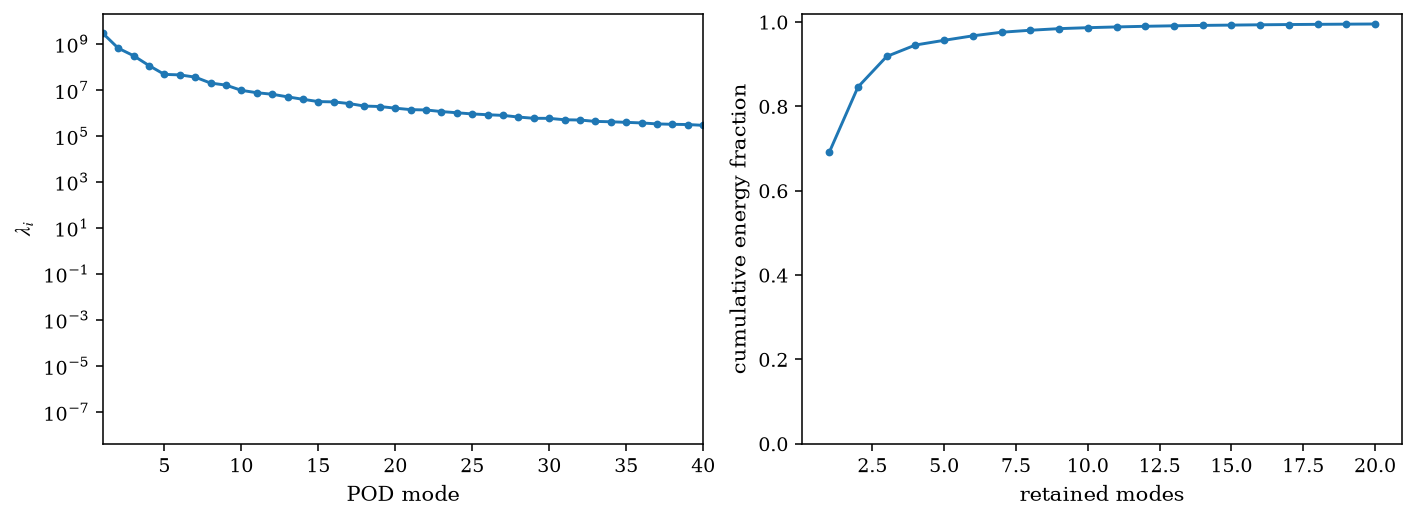

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\POD\pod_energy.png


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), layout='constrained')
mode_id = np.arange(1, eigenvalues.size + 1)
axes[0].semilogy(mode_id, eigenvalues, 'o-', ms=3)
axes[0].set_xlabel('POD mode')
axes[0].set_ylabel(r'$\lambda_i$')
axes[0].set_xlim(1, min(40, eigenvalues.size))
axes[1].plot(np.arange(1, rank + 1), cumulative_energy, 'o-', ms=3)
axes[1].set_xlabel('retained modes')
axes[1].set_ylabel('cumulative energy fraction')
axes[1].set_ylim(0, 1.02)
fig.savefig(OUT_DIR / 'pod_energy.png')
plt.show()
print(OUT_DIR / 'pod_energy.png')

绘制前四个 POD 模态的 `u、v` 分量。

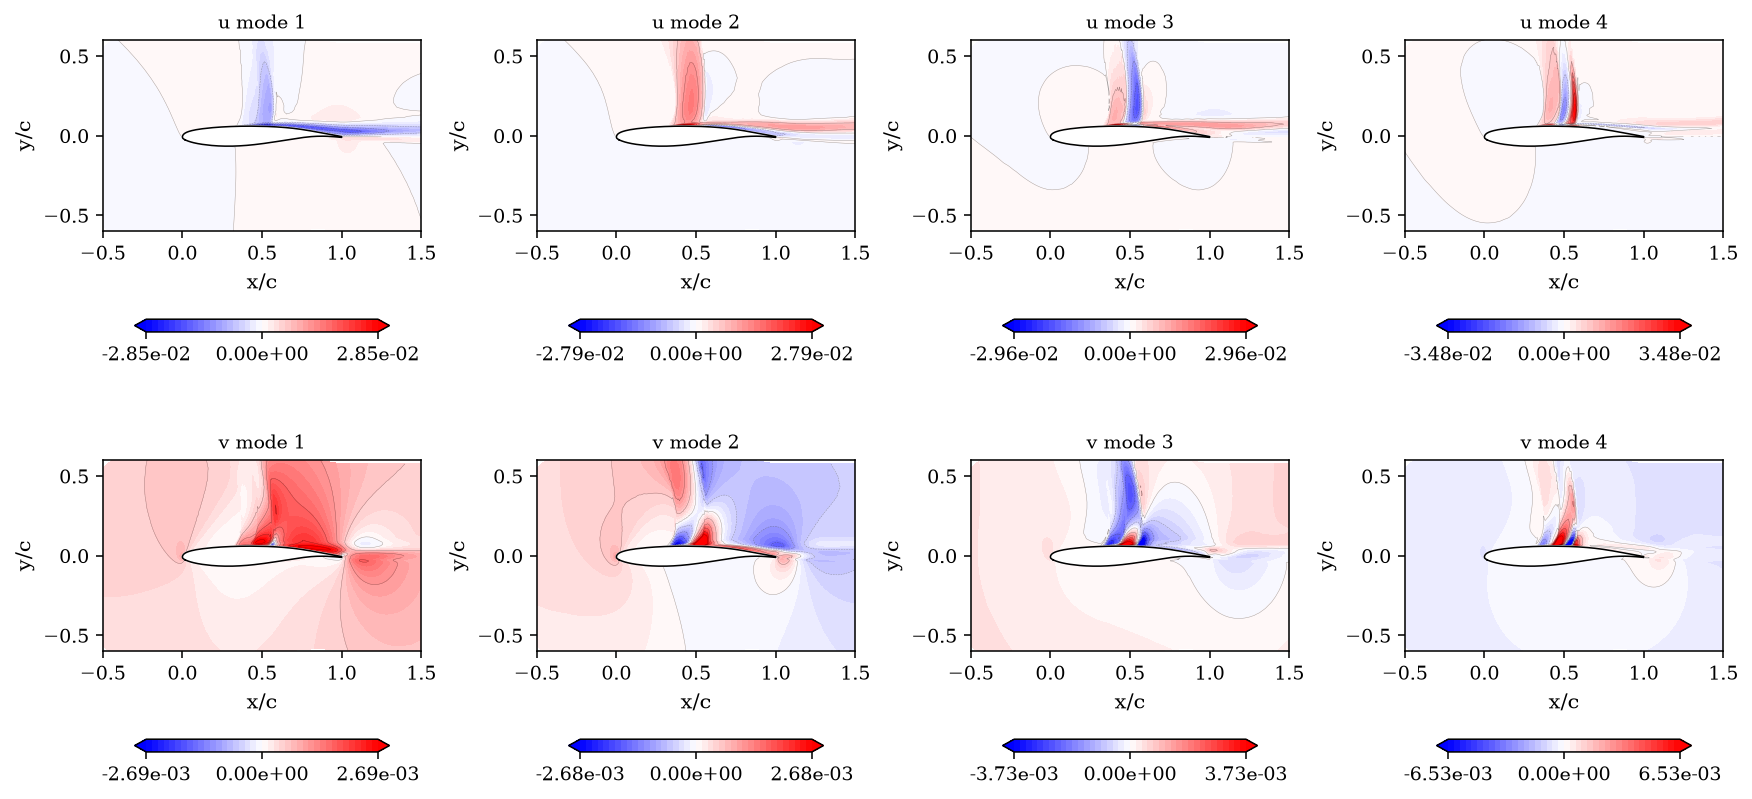

wall edges: 474, wall nodes: 474, chord: 0.230611
local triangles: 73183, masked: 21347
c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\POD\pod_modes_1_4.png


In [6]:
mesh_path = CASE_DIR / 'mesh.txt'
mesh_lines = mesh_path.read_text(encoding='utf-8').splitlines()
mesh_node_count = int(mesh_lines[0].split()[2])
mesh_nodes = np.asarray([[float(parts[1]), float(parts[2])] for parts in (line.split() for line in mesh_lines[5:5 + mesh_node_count])])
wall_start = mesh_lines.index('wall')
wall_end = mesh_lines.index('(end)', wall_start)
wall_edges = np.asarray([[int(parts[1]) - 1, int(parts[2]) - 1] for parts in (line.split() for line in mesh_lines[wall_start + 1:wall_end]) if len(parts) >= 4])
wall_neighbours = {}
for first_node, second_node in wall_edges:
    wall_neighbours.setdefault(first_node, []).append(second_node)
    wall_neighbours.setdefault(second_node, []).append(first_node)
wall_start_node = min(wall_neighbours)
wall_order = [wall_start_node]
previous_node = None
current_node = wall_start_node
while True:
    candidates = wall_neighbours[current_node]
    next_node = candidates[0] if candidates[0] != previous_node else candidates[1]
    if next_node == wall_start_node:
        break
    wall_order.append(next_node)
    previous_node, current_node = current_node, next_node

wall_mesh = mesh_nodes[np.asarray(wall_order)]
wall_data_indices = np.asarray([np.argmin((x - point[0]) ** 2 + (y - point[1]) ** 2) for point in wall_mesh])
wall = np.column_stack((x[wall_data_indices], y[wall_data_indices]))
x_le = wall[:, 0].min()
y_center = wall[:, 1].mean()
CHORD = wall[:, 0].max() - x_le
x_norm = (x - x_le) / CHORD
y_norm = (y - y_center) / CHORD
wall_norm = np.column_stack(((wall[:, 0] - x_le) / CHORD, (wall[:, 1] - y_center) / CHORD))
x_plot = (-0.5, 1.5)
y_plot = (-0.6, 0.6)

body = wall_norm
body_path = MplPath(body, closed=True)

near = (
    (x_norm >= x_plot[0] - 0.05)
    & (x_norm <= x_plot[1] + 0.05)
    & (y_norm >= y_plot[0] - 0.05)
    & (y_norm <= y_plot[1] + 0.05)
)
tri = mtri.Triangulation(x_norm[near], y_norm[near])
tri_mask = mtri.TriAnalyzer(tri).get_flat_tri_mask(min_circle_ratio=0.01, rescale=True)
triangle_centers = np.column_stack((
    x_norm[near][tri.triangles].mean(axis=1),
    y_norm[near][tri.triangles].mean(axis=1),
))
tri_mask |= body_path.contains_points(triangle_centers)
tri.set_mask(tri_mask)

def plot_field(ax, values, title, levels=41):
    local_values = values[near]
    limit = np.percentile(np.abs(local_values), 99.5)
    level_values = np.linspace(-limit, limit, levels)
    image = ax.tricontourf(
        tri,
        local_values,
        levels=level_values,
        cmap='bwr',
        extend='both',
    )
    ax.tricontour(
        tri,
        local_values,
        levels=level_values[::4],
        colors='k',
        linewidths=0.25,
        alpha=0.35,
    )
    ax.fill(body[:, 0], body[:, 1], color='white', zorder=3)
    ax.plot(body[:, 0], body[:, 1], color='k', linewidth=0.8, zorder=4)
    ax.set_xlim(*x_plot)
    ax.set_ylim(*y_plot)
    ax.set_aspect('equal', adjustable='box')
    ax.set_title(title)
    ax.set_xlabel('x/c')
    ax.set_ylabel('y/c')
    return image

n_plot = min(4, rank)
fig, axes = plt.subplots(2, n_plot, figsize=(3.1 * n_plot, 6.0), squeeze=False, layout='constrained')
for j in range(n_plot):
    image_u = plot_field(axes[0, j], pod_modes_u[j], f'u mode {j + 1}')
    image_v = plot_field(axes[1, j], pod_modes_v[j], f'v mode {j + 1}')
    fig.colorbar(image_u, ax=axes[0, j], orientation='horizontal', pad=0.08, shrink=0.8, ticks=np.linspace(image_u.norm.vmin, image_u.norm.vmax, 3), format='%.2e')
    fig.colorbar(image_v, ax=axes[1, j], orientation='horizontal', pad=0.08, shrink=0.8, ticks=np.linspace(image_v.norm.vmin, image_v.norm.vmax, 3), format='%.2e')
fig.savefig(OUT_DIR / 'pod_modes_1_4.png')
plt.show()
print(f'wall edges: {wall_edges.shape[0]}, wall nodes: {len(wall_order)}, chord: {CHORD:.6f}')
print(f'local triangles: {tri.triangles.shape[0]}, masked: {int(np.count_nonzero(tri_mask))}')
print(OUT_DIR / 'pod_modes_1_4.png')

查看前两个模态的时间振幅及其频谱。

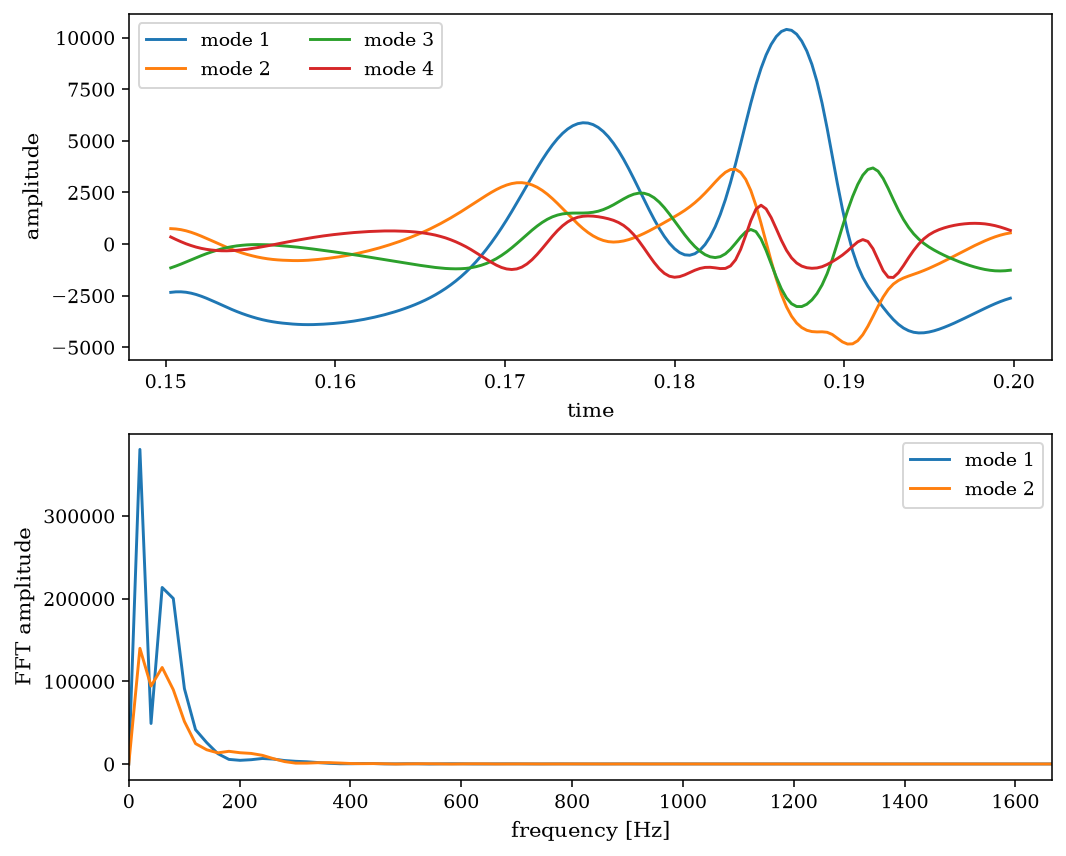

c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\POD\pod_amplitudes_spectrum.png


In [7]:
n_amplitude_plot = min(4, rank)
fig, axes = plt.subplots(2, 1, figsize=(7.5, 6.0), layout='constrained')
for j in range(n_amplitude_plot):
    axes[0].plot(time, amplitudes[j].real, label=f'mode {j + 1}')
axes[0].set_xlabel('time')
axes[0].set_ylabel('amplitude')
axes[0].legend(ncol=2)

dt = float(np.median(np.diff(time)))
frequency = np.fft.rfftfreq(n_snapshots, d=dt)
for j in range(min(2, rank)):
    spectrum = np.abs(np.fft.rfft(amplitudes[j].real - amplitudes[j].real.mean()))
    axes[1].plot(frequency, spectrum, label=f'mode {j + 1}')
axes[1].set_xlabel('frequency [Hz]')
axes[1].set_ylabel('FFT amplitude')
axes[1].set_xlim(0, frequency[-1])
axes[1].legend()
fig.savefig(OUT_DIR / 'pod_amplitudes_spectrum.png')
plt.show()
print(OUT_DIR / 'pod_amplitudes_spectrum.png')

重构速度扰动并保存模态、振幅、均值场和能量信息。

In [8]:
reconstructed = pod_modes @ amplitudes
reconstruction_error = np.linalg.norm(A - reconstructed, axis=0) / np.linalg.norm(A, axis=0)

np.savez_compressed(
    OUT_DIR / 'pod_results.npz',
    x=x,
    y=y,
    time=time,
    steps=steps,
    mean_u=mean_velocity[:, 0],
    mean_v=mean_velocity[:, 1],
    pod_modes_u=pod_modes_u,
    pod_modes_v=pod_modes_v,
    amplitudes=amplitudes,
    eigenvalues=eigval,
    energy_fraction=energy_fraction,
    cumulative_energy=cumulative_energy,
    reconstruction_error=reconstruction_error,
    fields=np.asarray(POD_FIELDS),
)

summary = pd.DataFrame({
    'mode': np.arange(1, rank + 1),
    'eigenvalue': eigval,
    'energy_fraction': energy_fraction,
    'cumulative_energy': cumulative_energy,
})
summary.to_csv(OUT_DIR / 'pod_energy.csv', index=False)

print(f'mean relative reconstruction error: {reconstruction_error.mean():.6e}')
print(f'max relative reconstruction error : {reconstruction_error.max():.6e}')
print(OUT_DIR / 'pod_results.npz')
print(OUT_DIR / 'pod_energy.csv')

mean relative reconstruction error: 7.509977e-02
max relative reconstruction error : 1.762924e-01
c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\POD\pod_results.npz
c:\Users\Administrator\Desktop\PurineCFD-Plugin\results\72\POD\pod_energy.csv
